# 08 Final leaderboard

Everything here is loaded from the forecasts saved in notebooks 01 to 07. Nothing is trained, and it runs in under a minute.

One leaderboard for every model and selection strategy, scored the same way: `utilsforecast` for WAPE, MAE, bias and RMSSE, then APC and coverage. It is ordered by information tier, then WAPE. Compare rows within a tier; each tier below the first uses more information than was available on the cutoff date:

- **historical_only**: data observed by the cutoff. This is the operational ranking.
- **planned_scenario**: also a promotion plan, stood in for by realized flags in the first four forecast weeks.
- **oracle**: realized promotions for all 14 weeks.
- **leaky_diagnostic**: realized future prices, or candidates chosen with the final-window actuals.

A selection strategy takes the highest tier among its candidates. Scores are on the final 14 weeks (cutoff 2025-04-09) and the rows every model forecasts. **That window was inspected while the notebooks were built, so these are exploratory benchmarks, not untouched holdout results.** A blank APC means the model has no forecasts from earlier origins.


In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from shared.prepare_data import load_panel, series_segments, TEST_CUTOFF, STABILITY_CUTOFFS
from shared.leaderboard import load_forecasts, leaderboard, breakdown, FOLDER, TIERS

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]
segments = series_segments(panel)

files = ["01_baselines", "02_ml_baseline", "03_exogenous", "03b_promotion_spikes", "03_catboost", "03_categorical", "03c_behavior_features", "04_global_vs_specialized", "04_partition_granularity", "05_horizon_strategies", "06_objectives", "07_model_selection"]
forecasts = load_forecasts(files)
forecasts = forecasts[~forecasts.model.isin(["Selected_per_SKU", "Average"])]    # preliminary versions from 01; 07 rebuilds both

## Leaderboard

Scored once. The tables below are slices of the same board, one per information tier.

In [3]:
board = leaderboard(forecasts, actuals, scope="test")
columns = ["model", "experiment", "wape", "bias", "mean_rmsse", "median_rmsse", "apc", "coverage"]

### historical_only

The operational ranking: models and selection strategies that use only data observed by the cutoff. The 15 best are shown; the full ranking is in `board` and `results/day1/leaderboard.csv`.

In [4]:
board[board.information_tier == "historical_only"][columns].head(15).round(3)

,model,experiment,wape,bias,mean_rmsse,median_rmsse,apc,coverage
0,Tour_P8_behavior_portfolio,07_model_selection,0.344,-0.035,1.249,0.664,0.107,1.0
1,lgbm_l1_cat_price_response,03c_behavior_features,0.344,-0.035,1.249,0.664,0.107,1.0
2,lgbm_l1_cat_class_agg,03c_behavior_features,0.345,-0.012,1.245,0.665,0.111,1.0
3,lgbm_l1_cat_combined,03c_behavior_features,0.345,-0.032,1.251,0.666,0.104,1.0
4,Average_top3_ml_behavior,07_model_selection,0.345,-0.032,1.249,0.668,0.104,1.0
5,lgbm_l1_cat_dept_class_agg,03c_behavior_features,0.345,-0.008,1.246,0.663,0.107,1.0
6,lgbm_l1_cat_subclass_agg,03c_behavior_features,0.346,-0.005,1.245,0.662,0.108,1.0
7,Average_top3_ml_categorical,07_model_selection,0.348,-0.038,1.243,0.661,0.101,1.0
8,lgbm_l1_cat_price,03c_behavior_features,0.348,-0.029,1.251,0.667,0.111,1.0
9,lgbm_l1_cat_dept_agg,03c_behavior_features,0.348,-0.013,1.253,0.670,0.112,1.0


### planned_scenario, oracle and leaky_diagnostic

In [5]:
for tier in TIERS[1:]:
    display(board[board.information_tier == tier][columns].round(3))

,model,experiment,wape,bias,mean_rmsse,median_rmsse,apc,coverage
107,lgbm_promo_calendar_planned,03_exogenous,0.360,-0.060,1.265,0.667,0.179,1.0
108,Select_planned_portfolio,07_model_selection,0.369,-0.003,1.265,0.671,0.118,1.0
109,Average_planned_all,07_model_selection,0.369,0.040,1.751,0.734,0.092,1.0
110,lgbm_adj_calendar_planned,03b_promotion_spikes,0.371,-0.102,1.298,0.696,0.175,1.0
111,lgbm_adj_planned,03b_promotion_spikes,0.372,-0.112,1.300,0.697,0.176,1.0
112,Select_planned_department,07_model_selection,0.373,-0.014,1.283,0.678,0.138,1.0
113,Select_planned_sku,07_model_selection,0.375,0.016,1.302,0.686,0.128,1.0
114,lgbm_promo_planned,03_exogenous,0.384,0.025,1.268,0.678,0.125,1.0


,model,experiment,wape,bias,mean_rmsse,median_rmsse,apc,coverage
115,lgbm_promo_calendar_oracle,03_exogenous,0.322,0.036,1.204,0.618,0.082,1.0
116,lgbm_adj_oracle,03b_promotion_spikes,0.333,0.015,1.236,0.633,0.087,1.0
117,lgbm_adj_calendar_oracle,03b_promotion_spikes,0.334,0.019,1.239,0.634,0.087,1.0
118,lgbm_promo_oracle,03_exogenous,0.395,0.113,1.263,0.681,0.089,1.0


,model,experiment,wape,bias,mean_rmsse,median_rmsse,apc,coverage
119,Best_in_hindsight_sku,07_model_selection,0.232,-0.054,0.892,0.533,NaN,1.0
120,lgbm_price_leaky,03_exogenous,0.416,0.237,1.235,0.654,0.085,1.0


The full board, with every column, is written to `results/day1/leaderboard.csv`. `eligible_series` counts series with a defined RMSSE scale (53+ weeks of history and a seasonal difference that is not always zero). `apc_coverage` is the share of a model's revision blocks inside the common APC population; blocks where any model's earlier forecast sums to zero are left out for all.

## Day 2 handoff

Day 2 continues on the same 2,000 series and the same final window, so its scores can sit next to these. Two things keep the comparison fair:

- Each Day 2 model needs an information tier. A model given realized future prices or promotions in `X_df` belongs in `oracle` or `leaky_diagnostic`, not next to the historical-only Day 1 models.
- A model or ensemble chosen with final-window scores is `leaky_diagnostic`.

Day 2's `bootcamp.leaderboard()` reads `model`, `lab`, `wape`, `mean_rmsse`, `median_rmsse` and `n_series` from this file, and should filter on `information_tier`. `results/day1/README.md` lists what else Day 2 needs to supply.

In [6]:
board.rename(columns={"experiment": "lab", "series": "n_series"}).round(5).to_csv(FOLDER / "leaderboard.csv", index=False)

### Forecasts for Day 2

`day2_handoff.parquet` holds the Day 1 models that Day 2 compares against, at the final cutoff and the two earlier cutoffs that APC needs, in the shared format. Day 2 can score its own forecasts against them without rerunning any Day 1 notebook; `results/day1/README.md` has the loading example.

In [7]:
handoff_models = {
    "Naive": "last observed week",
    "SeasonalNaive": "same week last year",
    "HistoricAverage": "mean of the history",
    "lgbm_baseline": "basic global LightGBM: L2, standardized target (02)",
    "lgbm_raw": "L2, raw target (02)",
    "lgbm_l1_raw": "L1, raw target (06)",
    "lgbm_tweedie_raw": "Tweedie 1.3, raw target (06)",
    "lgbm_l1_std": "L1, standardized target (06)",
    "lgbm_l1_std_categorical": "L1 plus department, class and subclass (03)",
    "lgbm_l1_cat_price_response": "plus historical price features; best historical-only model (03c)",
    "Average_top3_ml": "top-three ML average, live-path pool (07)",
    "Average_top3_ml_behavior": "top-three ML average, largest pool (07)",
    "lgbm_promo_calendar_planned": "promotion plan for the first 4 weeks (03)",
    "lgbm_promo_calendar_oracle": "realized promotions for all 14 weeks (03)",
    "lgbm_price_leaky": "realized future prices (03)",
}
handoff = forecasts[forecasts.model.isin(handoff_models) & forecasts.cutoff.isin([TEST_CUTOFF] + list(STABILITY_CUTOFFS))]
handoff[["unique_id", "cutoff", "ds", "model", "yhat", "experiment", "information_tier"]].to_parquet(FOLDER / "day2_handoff.parquet", index=False)

pd.DataFrame({"description": handoff_models}).join(board.set_index("model")[["information_tier", "wape", "bias", "mean_rmsse", "apc"]]).round(3)

,description,information_tier,wape,bias,mean_rmsse,apc
Naive,last observed week,historical_only,0.470,0.066,1.332,0.325
SeasonalNaive,same week last year,historical_only,0.438,-0.037,1.525,0.000
HistoricAverage,mean of the history,historical_only,0.426,-0.011,1.367,0.010
lgbm_baseline,"basic global LightGBM: L2, standardized target...",historical_only,0.419,0.109,1.302,0.091
lgbm_raw,"L2, raw target (02)",historical_only,0.505,0.215,12.000,0.164
lgbm_l1_raw,"L1, raw target (06)",historical_only,0.375,-0.073,1.229,0.166
lgbm_tweedie_raw,"Tweedie 1.3, raw target (06)",historical_only,0.455,0.147,1.346,0.165
lgbm_l1_std,"L1, standardized target (06)",historical_only,0.369,-0.003,1.265,0.118
lgbm_l1_std_categorical,"L1 plus department, class and subclass (03)",historical_only,0.350,-0.020,1.257,0.113
lgbm_l1_cat_price_response,plus historical price features; best historica...,historical_only,0.344,-0.035,1.249,0.107


### Compact benchmark file

`day2_benchmarks.parquet` is the short version: five representative historical-only models, chosen to span the course rather than to be the five best. Same rows and cutoffs as above.

In [8]:
benchmarks = ["Naive", "SeasonalNaive", "lgbm_baseline", "lgbm_l1_std_categorical", "lgbm_l1_cat_price_response"]
compact = handoff[handoff.model.isin(benchmarks)].sort_values(["model", "cutoff", "unique_id", "ds"])
compact[["unique_id", "cutoff", "ds", "model", "yhat", "experiment", "information_tier"]].to_parquet(FOLDER / "day2_benchmarks.parquet", index=False)
compact.groupby(["model", "cutoff"]).size().unstack()

cutoff,2025-02-12,2025-03-12,2025-04-09
model,,,
Naive,28000,28000,28000
SeasonalNaive,28000,28000,28000
lgbm_baseline,28000,28000,28000
lgbm_l1_cat_price_response,28000,28000,28000
lgbm_l1_std_categorical,28000,28000,28000


## Accuracy against stability, historical-only

Left is more stable (smaller revisions between runs four weeks apart), up is more accurate.

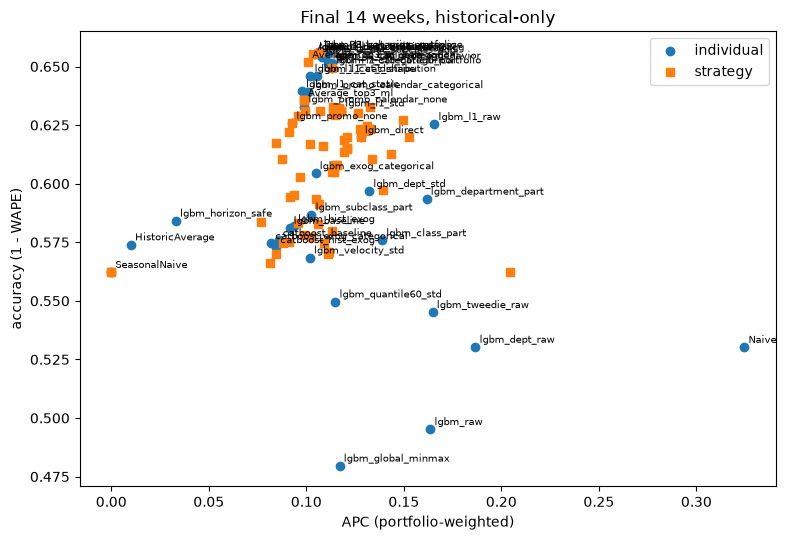

In [9]:
points = board[(board.information_tier == "historical_only") & board.apc.notna()]
strategy = points.model.str.startswith(("Select_", "Average_", "Tour_", "Hybrid_"))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(points[~strategy].apc, points[~strategy].accuracy, marker="o", label="individual")
ax.scatter(points[strategy].apc, points[strategy].accuracy, marker="s", label="strategy")
for row in pd.concat([points[~strategy], points[strategy].nsmallest(5, "wape")]).itertuples():
    ax.annotate(row.model, (row.apc, row.accuracy), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="APC (portfolio-weighted)", ylabel="accuracy (1 - WAPE)", title="Final 14 weeks, historical-only")
ax.legend()
plt.tight_layout()

## By horizon, volume and intermittency

A few historical-only models and strategies, on the same pipeline. Segments are fixed from each product's history up to the final cutoff.

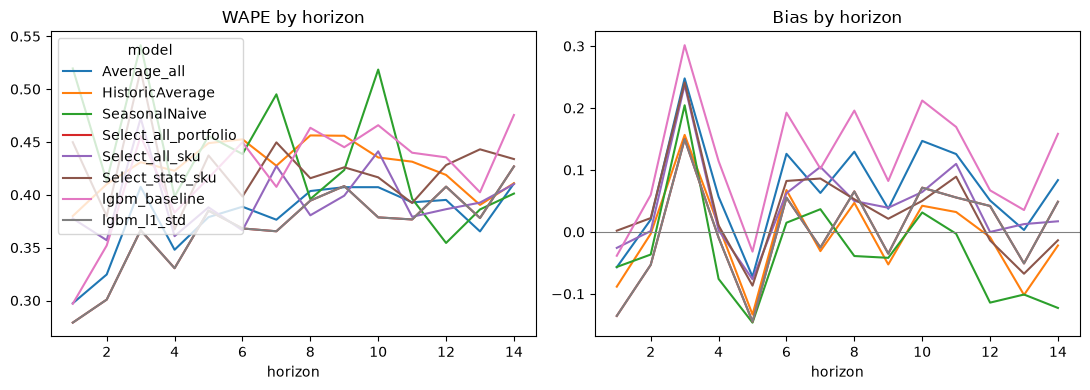

In [10]:
focus = ["HistoricAverage", "SeasonalNaive", "lgbm_baseline", "lgbm_l1_std", "Select_stats_sku", "Select_all_sku", "Select_all_portfolio", "Average_all"]
pool = forecasts[forecasts.model.isin(focus)]
by_horizon = breakdown(pool, actuals, "horizon")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_horizon.pivot(index="horizon", columns="model", values="wape").plot(ax=axes[0], title="WAPE by horizon")
by_horizon.pivot(index="horizon", columns="model", values="bias").plot(ax=axes[1], title="Bias by horizon", legend=False)
axes[1].axhline(0, color="grey", lw=0.8)
plt.tight_layout()

In [11]:
volume = breakdown(pool, actuals, "volume", segments=segments)
zeros = breakdown(pool, actuals, "intermittency", segments=segments)
pd.concat({
    "wape by volume": volume.pivot(index="model", columns="volume", values="wape")[["low", "mid", "high"]],
    "bias by volume": volume.pivot(index="model", columns="volume", values="bias")[["low", "mid", "high"]],
    "wape by intermittency": zeros.pivot(index="model", columns="intermittency", values="wape")[["regular", "some_zeros", "zero_heavy"]],
    "bias by intermittency": zeros.pivot(index="model", columns="intermittency", values="bias")[["regular", "some_zeros", "zero_heavy"]],
}, axis=1).round(3)

wape by volume               bias by volume         \
                                low    mid   high            low    mid   
model                                                                     
Average_all                   0.732  0.414  0.367         -0.407 -0.028   
HistoricAverage               0.843  0.495  0.411         -0.663 -0.139   
SeasonalNaive                 0.918  0.558  0.416         -0.698 -0.162   
Select_all_portfolio          0.756  0.403  0.358         -0.608 -0.105   
Select_all_sku                0.818  0.443  0.382         -0.588 -0.050   
Select_stats_sku              0.851  0.470  0.412         -0.624 -0.082   
lgbm_baseline                 0.781  0.446  0.409         -0.544 -0.008   
lgbm_l1_std                   0.756  0.403  0.358         -0.608 -0.105   

                            wape by intermittency                        \
                       high               regular some_zeros zero_heavy   
model                                                                     
Average_all           0.082                 0.349      0.370      0.947   
HistoricAverage       0.014                 0.400      0.422      0.911   
SeasonalNaive        -0.011                 0.371      0.503      0.988   
Select_all_portfolio  0.019                 0.338      0.371      0.874   
Select_all_sku        0.060                 0.355      0.374      1.284   
Select_stats_sku      0.053                 0.357      0.460      1.288   
lgbm_baseline         0.134                 0.388      0.405      1.081   
lgbm_l1_std           0.019                 0.338      0.371      0.874   

                     bias by intermittency                        
                                   regular some_zeros zero_heavy  
model                                                             
Average_all                          0.096      0.033     -0.229  
HistoricAverage                      0.086     -0.116     -0.731  
SeasonalNaive                        0.055     -0.110     -0.962  
Select_all_portfolio                 0.046     -0.041     -0.503  
Select_all_sku                       0.069     -0.017      0.025  
Select_stats_sku                     0.077     -0.045     -0.118  
lgbm_baseline                        0.154      0.063     -0.229  
lgbm_l1_std                          0.046     -0.041     -0.503